Accuracy  : 65.83333333333333 %


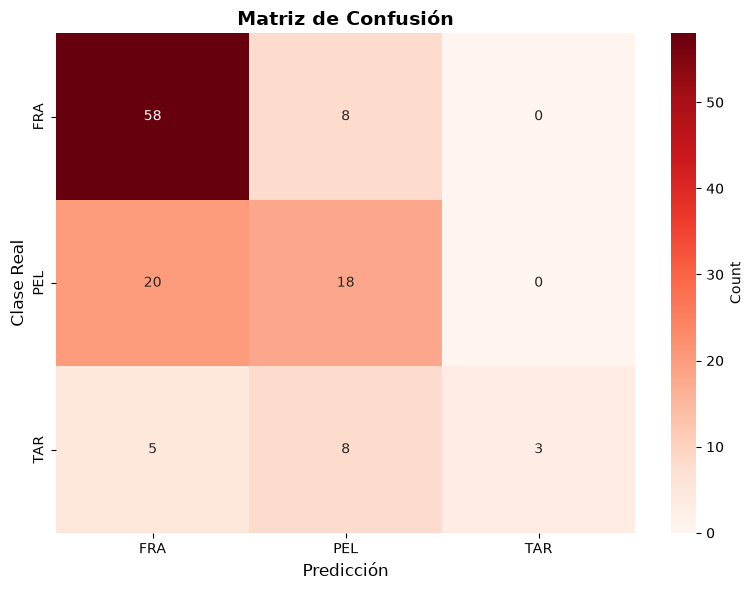

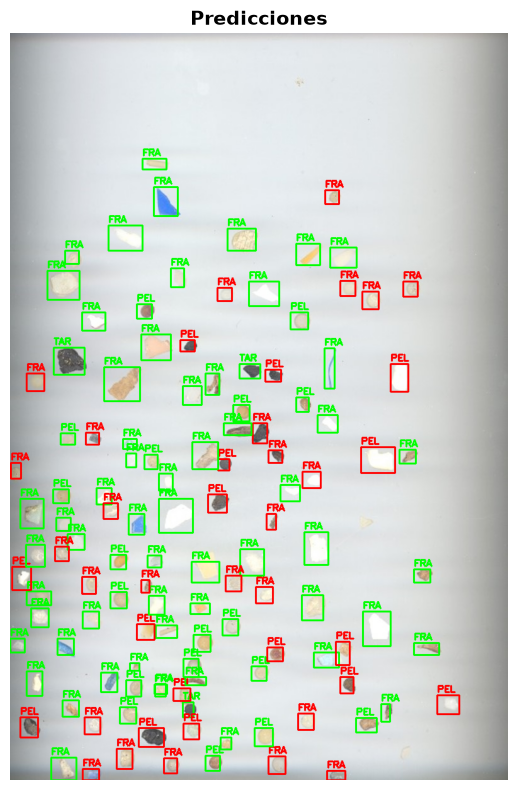

In [2]:
import cv2
import csv
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

train_imgs = {
    "FRA": "FRA.png",
    "PEL": "PEL.png",
    "TAR": "TAR.png"
}

test = "test.jpg"
test_csv = "MPs_test_bbs.csv"

# Función que extrae las características de la imagen
def extract_features(img):
    
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    
    # Umbralizamos la imagen con Otsu
    _, mask = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    
    # Buscamos el fondo de la imagen "mask == 255 pixeles blancos | mask == 0 pixeles negros".
    # En caso de tener un fondo blanco, incertiremos los valores de la imagen umbralizada para
    # que las partículas tengan color blanco y el fondo sea negro.
    if np.mean(gray[mask == 255]) > np.mean(gray[mask == 0]):
        mask = cv2.bitwise_not(mask)
    
    # Buscamos los contornos
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    # Seleccionamos el contorno más grande
    cnt = max(contours, key=cv2.contourArea)
    
    # Obtenemos las características del contorno
    x, y, w, h = cv2.boundingRect(cnt)
    area = cv2.contourArea(cnt)
    perimeter = cv2.arcLength(cnt, True)
    compacidad = (perimeter ** 2) / (area + 1e-9)
    rel_area_box = area / (w * h + 1e-9)
    aspect_ratio = w / (h + 1e-9)
    
    # Elipse:
    # Comprobamos que el contorno sea al menos de 5 puntos ya que este es el mínimo de "fitEllipse()"
    if len(cnt) >= 5:
        try:
            (_, _), (MA, ma), _ = cv2.fitEllipse(cnt) #Obtenemos las longitudes de los ejes
            rel_ejes = max(MA, ma) / (min(MA, ma) + 1e-9) #Ejes similares: ~= 1 | Eje mayor que otro: > 1
        except:
            rel_ejes = 0
    else:
        rel_ejes = 0
    
    # Centroide:
    # Utilizamos el momento para obtener las coordenadas horizontales y verticales.
    # El momento de orden cero (00) se relacciona con el area
    # El momento de primer orden (10) se relacciona con la coordenada horizontal
    # El momento de primer orden (01) se relacciona con la coordenada vertical
    M = cv2.moments(cnt)
    
    # Evitamos el error de dividir entre 0
    if M["m00"] != 0:
        cx = int(M["m10"] / M["m00"])
        cy = int(M["m01"] / M["m00"])
    else:
        cx, cy = 0, 0
    
    # Distancias desde el centroide hasta el contorno
    # "cv2.norm" Calcula la norma del vector resultante. d = sqrt[(cx-x)^2+(cy-y)^2]

    dists = [cv2.norm(np.array([cx, cy], dtype=np.float32) - p[0].astype(np.float32)) for p in cnt]
    rel_dist = min(dists) / (max(dists) + 1e-9) if len(dists) > 0 else 0
    
    # Colores:
    # Medidas RGB de la imagen
    mean_b = np.mean(img[mask == 255, 0]) if np.any(mask == 255) else 0
    mean_g = np.mean(img[mask == 255, 1]) if np.any(mask == 255) else 0
    mean_r = np.mean(img[mask == 255, 2]) if np.any(mask == 255) else 0
    
    # Desviación estándar RGB de la imagen
    std_b = np.std(img[mask == 255, 0]) if np.any(mask == 255) else 0
    std_g = np.std(img[mask == 255, 1]) if np.any(mask == 255) else 0
    std_r = np.std(img[mask == 255, 2]) if np.any(mask == 255) else 0
    
    # Media, saturación y brillo de la imagen
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    mean_h = np.mean(hsv[mask == 255, 0]) if np.any(mask == 255) else 0
    mean_s = np.mean(hsv[mask == 255, 1]) if np.any(mask == 255) else 0
    mean_v = np.mean(hsv[mask == 255, 2]) if np.any(mask == 255) else 0
    
    # Solidez
    hull = cv2.convexHull(cnt)
    hull_area = cv2.contourArea(hull)
    solidity = area / (hull_area + 1e-9)
    
    # Extensión
    extent = area / (w * h + 1e-9)
    
    return [
        area, perimeter, compacidad, rel_area_box, aspect_ratio, rel_ejes, rel_dist,
        mean_r, mean_g, mean_b, std_r, std_g, std_b,
        mean_h, mean_s, mean_v, solidity, extent
    ]


# Extraemos las características de entrenamiento
patterns = {}
X_train = []
y_train = []

for label, path in train_imgs.items():
    img = cv2.imread(path)
    features = extract_features(img)
    patterns[label] = np.array(features)
    X_train.append(features)
    y_train.append(label)

# Normalizamos las características
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Entrenamiento del clasificador "Random Forest":
# n_estimators: indica el número de árboles de decisión que tendrá el bosque
# random_state: se le da un valor para la aletoriedad (semilla)
# max_depth: profundidad máxima de cada árbol
clf = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=10)
# Entrenamiento
clf.fit(X_train_scaled, y_train)

# Imagen de prueba
img_test = cv2.imread(test)
y_true = []
y_pred = []

# Leemos el csv con los datos de la imagen
with open(test_csv, newline="") as file:
    reader = csv.DictReader(file)
    for row in reader:
        label = row["label"]
        
        #Obtenemos las coordenadas
        x_min, y_min, x_max, y_max = map(int, [
            row["x_min"], row["y_min"], row["x_max"], row["y_max"]
        ])
        
        # Recortamos la partícula que se encuentra en las siguientes coordenadas:
        crop = img_test[y_min:y_max, x_min:x_max]
        # Obtenemos las características de la partícula recortada
        features = extract_features(crop)
        
        if features is None:
            pred = "FRA"
        else:
            # Se aplica al vector de características los mismos parámetros de estandarización 
            # aprendidos durante el entrenamiento.
            features_scaled = scaler.transform([features])
            # Se predice la etiqueta de la partícula
            pred = clf.predict(features_scaled)[0]
        
        y_true.append(label)
        y_pred.append(pred)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted', zero_division=0)
recall = recall_score(y_true, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)

print(f"Accuracy  :", accuracy*100,"%")

# Matriz confusión
labels = ["FRA", "PEL", "TAR"]
cm = confusion_matrix(y_true, y_pred, labels=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Reds",
            xticklabels=labels, yticklabels=labels, cbar_kws={'label': 'Count'})
plt.xlabel("Predicción", fontsize=12)
plt.ylabel("Clase Real", fontsize=12)
plt.title("Matriz de Confusión", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Imagen
colores = {"FRA": (0, 0, 255), "PEL": (0, 255, 0), "TAR": (255, 0, 0)}
img_display = img_test.copy()

with open(test_csv, newline="") as file:
    reader = csv.DictReader(file)
    for i, row in enumerate(reader):
        x_min, y_min, x_max, y_max = map(int, [
            row["x_min"], row["y_min"], row["x_max"], row["y_max"]
        ])
        pred = y_pred[i]
        true_label = y_true[i]
        
        # Color: green if correct, red if incorrect
        is_correct = (pred == true_label)
        color = (0, 255, 0) if is_correct else (0, 0, 255)
        
        cv2.rectangle(img_display, (x_min, y_min), (x_max, y_max), color, 2)
        cv2.putText(img_display, f"{pred}", (x_min, y_min - 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(img_display, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title("Predicciones", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [4]:

"""Recuento de monedas con webcam; ESPACIO captura y ESC permite otra foto."""

import cv2
import numpy as np
from datetime import datetime
from pathlib import Path

CAMARA_ID = 0
ANCHO_CAMARA = 1280
ALTO_CAMARA = 720
ficha_ideal_diametro = 13.5
umbral = 20
tolerancia = 0.06

monedas_diametro = {
    "1cent": 16.25, "2cent": 18.75, "5cent": 21.25,
    "10cent": 19.75, "20cent": 22.25, "50cent": 24.25,
    "1euro": 23.25, "2euros": 25.75
}
valores = {
    "1cent": 0.01, "2cent": 0.02, "5cent": 0.05,
    "10cent": 0.10, "20cent": 0.20, "50cent": 0.50,
    "1euro": 1.00, "2euros": 2.00
}
metal = {
    "1cent": "cobre", "2cent": "cobre", "5cent": "cobre",
    "10cent": "oro", "20cent": "oro", "50cent": "oro",
    "1euro": "bimetal", "2euros": "bimetal"
}

def procesar_imagen(img, ruta_captura):
    # Analiza una captura y devuelve la imagen con las monedas marcadas.
    if img is None or img.size == 0:
        print("Error: la captura esta vacia.")
        return None

    alto, ancho = img.shape[:2]
    kernel = np.ones((5, 5), np.uint8)

    def distancia_color(imagen, fondo):
        a = cv2.cvtColor(cv2.GaussianBlur(imagen, (5, 5), 0), cv2.COLOR_BGR2LAB).astype(float)
        b = cv2.cvtColor(np.clip(fondo, 0, 255).astype(np.uint8), cv2.COLOR_BGR2LAB).astype(float)
        return np.linalg.norm(a - b, axis=2)

    # Estima el color del papel para separar las monedas del fondo.
    pequena = cv2.resize(img, None, fx=0.12, fy=0.12, interpolation=cv2.INTER_AREA)
    ksize = min(31, min(pequena.shape[:2]))
    if ksize % 2 == 0:
        ksize -= 1
    ksize = max(3, ksize)
    fondo = cv2.resize(cv2.medianBlur(pequena, ksize), (ancho, alto), interpolation=cv2.INTER_LINEAR)
    dif = distancia_color(img, fondo)
    dif = np.maximum(dif - np.percentile(dif, 10), 0)
    _, mascara = cv2.threshold(dif.astype(np.uint8), umbral, 255, cv2.THRESH_BINARY)
    mascara = cv2.morphologyEx(mascara, cv2.MORPH_CLOSE, kernel, iterations=3)
    excluir = cv2.dilate(mascara, np.ones((31, 31), np.uint8))

    n = 20
    bh, bw = max(1, alto // n), max(1, ancho // n)
    fondo_peq = np.full((n, n, 3), np.nan, np.float32)
    for i in range(n):
        for j in range(n):
            trozo = img[i * bh:(i + 1) * bh, j * bw:(j + 1) * bw]
            libres = trozo[excluir[i * bh:(i + 1) * bh, j * bw:(j + 1) * bw] == 0]
            if len(libres) > 0.25 * trozo[:, :, 0].size:
                fondo_peq[i, j] = np.median(libres, axis=0)
    pixeles_fondo = img[excluir == 0]
    if len(pixeles_fondo) == 0:
        mediana_fondo = np.median(img.reshape(-1, 3), axis=0)
    else:
        mediana_fondo = np.median(pixeles_fondo, axis=0)
    fondo_peq[np.isnan(fondo_peq[:, :, 0])] = mediana_fondo
    fondo = cv2.resize(fondo_peq, (ancho, alto), interpolation=cv2.INTER_CUBIC)
    dif = distancia_color(img, fondo)

    _, mascara = cv2.threshold(dif.astype(np.uint8), umbral, 255, cv2.THRESH_BINARY)
    mascara = cv2.morphologyEx(mascara, cv2.MORPH_CLOSE, kernel, iterations=2)
    mascara = cv2.morphologyEx(mascara, cv2.MORPH_OPEN, kernel, iterations=1)
    contornos_crudos, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # Filtra ruido, objetos pegados al borde y formas poco circulares.
    contornos = []
    margen_borde = max(3, int(0.004 * min(alto, ancho)))
    area_minima = 0.0003 * alto * ancho
    for c in contornos_crudos:
        area_c = cv2.contourArea(c)
        if area_c < area_minima:
            continue

        x, y, w, h = cv2.boundingRect(c)
        if (x <= margen_borde or y <= margen_borde or
                x + w >= ancho - margen_borde or y + h >= alto - margen_borde):
            print(f"Ruido descartado en el borde: x={x}, y={y}, w={w}, h={h}")
            continue

        relacion = w / float(max(h, 1))
        perimetro = cv2.arcLength(c, True)
        circularidad = (4.0 * np.pi * area_c) / (perimetro * perimetro + 1e-9)
        if not (0.55 <= relacion <= 1.80) or circularidad < 0.22:
            continue
        contornos.append(c)

    if not contornos:
        print("No se detectaron objetos circulares. Revisa el fondo y la iluminacion.")
        return mostrar_mensaje(img, "No se detectaron objetos circulares")

    # Mide el borde de cada objeto siguiendo radios desde su centro.
    n_angulos, n_radios = 360, 240
    angulos = np.linspace(0, 2 * np.pi, n_angulos, endpoint=False)
    cosenos, senos = np.cos(angulos), np.sin(angulos)

    def medir_diametro(cx, cy, radio):
        radios = np.linspace(radio * 0.60, radio * 1.20, n_radios)
        mx = (cx + np.outer(cosenos, radios)).astype(np.float32)
        my = (cy + np.outer(senos, radios)).astype(np.float32)
        perfil = cv2.remap(dif, mx, my, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
        nivel = 0.5 * np.percentile(perfil[:, :n_radios // 3], 75, axis=1)
        dentro = perfil >= nivel[:, None]
        if dentro.any(axis=1).sum() < 0.6 * n_angulos:
            return 2 * radio
        idx = n_radios - 1 - np.argmax(dentro[:, ::-1], axis=1)
        r_borde = radios[idx]
        mediana = float(np.median(r_borde))
        buenos = r_borde[np.abs(r_borde - mediana) < 0.06 * mediana]
        return 2 * float(np.median(buenos if len(buenos) > 20 else r_borde))

    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    lab_fondo = cv2.cvtColor(fondo.astype(np.uint8), cv2.COLOR_BGR2LAB)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    diametros, centros, rojez, metales = [], [], [], []

    for c in contornos:
        (cx, cy), radio = cv2.minEnclosingCircle(cv2.convexHull(c))
        for _ in range(2):
            radio = medir_diametro(cx, cy, radio) / 2

        def disco(ri, ro):
            m = np.zeros((alto, ancho), np.uint8)
            cv2.circle(m, (int(cx), int(cy)), max(3, int(radio * ro)), 255, -1)
            if ri:
                cv2.circle(m, (int(cx), int(cy)), int(radio * ri), 0, -1)
            return m > 0

        interior = disco(0, 0.85)
        delta = float(lab[:, :, 1][interior].mean() - lab_fondo[:, :, 1][interior].mean())

        plata = min(hsv[:, :, 1][disco(0, 0.55)].mean(), hsv[:, :, 1][disco(0.80, 0.95)].mean())

        tono = float(hsv[:, :, 0][interior].mean())
        rojez.append(delta)
        if plata < 60:
            metales.append("bimetal")
        elif delta > 8 or tono < 17:
            metales.append("cobre")
        elif delta < 4 or tono > 18.5:
            metales.append("oro")
        else:
            metales.append(None)
        diametros.append(2 * radio)
        centros.append((cx, cy))

    print("Objetos detectados:", len(diametros))
    if not diametros:
        print("No hay objetos suficientes para medir.")
        return mostrar_mensaje(img, "No hay objetos suficientes para medir")

    # La ficha roja se selecciona automáticamente por su color.
    i_ficha = int(np.argmax(rojez))

    if rojez[i_ficha] < 10:
        print("Error: no se reconoce la ficha roja de referencia de 13,5 mm.")
        return mostrar_mensaje(img, "No se reconoce la ficha roja de referencia")

    ficha_real_diametro = diametros[i_ficha]
    escala = ficha_ideal_diametro / ficha_real_diametro
    print(f"Ficha de referencia detectada y excluida del recuento: centro "
          f"({centros[i_ficha][0]:.0f}, {centros[i_ficha][1]:.0f}), "
          f"diametro {ficha_real_diametro:.1f} px -> {1 / escala:.1f} px/mm")

    # La ficha fija la escala en píxeles por milímetro y no se cuenta.
    for lista in (diametros, centros, rojez, metales):
        lista.pop(i_ficha)

    for i in reversed([k for k, d in enumerate(diametros) if d * escala > 28]):
        cx, cy = centros[i]
        radio_ficha = ficha_real_diametro / 2
        gris = cv2.GaussianBlur(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), (9, 9), 2)
        circulos = cv2.HoughCircles(gris, cv2.HOUGH_GRADIENT, dp=1.2,
                                    minDist=int(1.25 * radio_ficha), param1=120, param2=65,
                                    minRadius=int(1.15 * radio_ficha),
                                    maxRadius=int(2.05 * radio_ficha))
        nuevos = [] if circulos is None else [(x, y, medir_diametro(x, y, r)) for x, y, r in circulos[0]
                                              if (x - cx) ** 2 + (y - cy) ** 2 <= (diametros[i] / 2) ** 2]
        if len(nuevos) >= 2:
            print(f"Objeto grande en ({cx:.0f}, {cy:.0f}) separado en {len(nuevos)} monedas")
            for lista in (diametros, centros, metales):
                lista.pop(i)
            for x, y, d in nuevos:
                diametros.append(d)
                centros.append((x, y))
                metales.append(None)
        else:

            print(f"Region grande descartada por no parecer una moneda: {diametros[i] * escala:.1f} mm")
            for lista in (diametros, centros, metales):
                lista.pop(i)

    validos = [i for i, d in enumerate(diametros)
               if 14.5 <= d * escala <= 28.0]
    descartados = len(diametros) - len(validos)
    if descartados:
        print(f"Medidas descartadas por tamano imposible para una moneda: {descartados}")
    diametros = [diametros[i] for i in validos]
    centros = [centros[i] for i in validos]
    metales = [metales[i] for i in validos]
    if not diametros:
        print("No quedan monedas validas tras filtrar el ruido.")
        return mostrar_mensaje(img, "No quedan monedas validas")

    mm = [d * escala for d in diametros]

    # Clasifica cada moneda por diámetro y, si es posible, por metal.
    def elegir(d_mm, grupo):
        candidatas = [m for m in monedas_diametro if grupo is None or metal[m] == grupo]
        mejor = min(candidatas, key=lambda m: abs(monedas_diametro[m] - d_mm))
        return mejor, abs(monedas_diametro[mejor] - d_mm) / monedas_diametro[mejor]

    contador_monedas = {m: 0 for m in monedas_diametro}
    contador, dinero_total, etiquetas = 0, 0.0, []
    print("\n  #   centro (px)      diametro   moneda")
    print("  " + "-" * 44)
    for k, ((cx, cy), d_mm, grupo) in enumerate(zip(centros, mm, metales), 1):
        mejor, error = elegir(d_mm, grupo)
        if error > tolerancia:
            mejor, error = elegir(d_mm, None)
        if error <= tolerancia:
            contador_monedas[mejor] += 1
            contador += 1
            dinero_total += valores[mejor]
            nombre = mejor
        else:
            nombre = "?"
        etiquetas.append((cx, cy, nombre, d_mm))
        print(f"  {k:2d}  ({cx:6.0f},{cy:6.0f})  {d_mm:7.2f} mm   {nombre}")

    print("\nContador de monedas:", contador_monedas)
    print("Total de monedas detectadas:", contador)
    print(f"Dinero total en la imagen: {dinero_total:.2f} euros")

    marcada = img.copy()
    for cx, cy, nombre, d_mm in etiquetas:
        cv2.circle(marcada, (int(cx), int(cy)), int(d_mm / escala / 2), (0, 255, 0), 3)
        texto = f"{nombre} {d_mm:.1f}"
        for grosor, color in ((5, (0, 0, 0)), (2, (0, 255, 255))):
            cv2.putText(marcada, texto, (int(cx) - 75, int(cy) - 8),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.9, color, grosor, cv2.LINE_AA)

    alto = marcada.shape[0]
    cv2.rectangle(marcada, (0, alto - 72), (marcada.shape[1], alto), (0, 0, 0), -1)
    cv2.putText(marcada, "ESC: otra foto | Q: salir", (15, alto - 48),
                cv2.FONT_HERSHEY_SIMPLEX, 0.65, (255, 255, 255), 2, cv2.LINE_AA)
    cv2.putText(marcada, f"Monedas: {contador} | Total: {dinero_total:.2f} euros",
                (15, alto - 18), cv2.FONT_HERSHEY_SIMPLEX,
                0.7, (255, 255, 255), 2, cv2.LINE_AA)

    ruta_resultado = str(Path(ruta_captura).with_name(Path(ruta_captura).stem + "_resultado.jpg"))
    cv2.imwrite(ruta_resultado, marcada)
    print("Imagen anotada guardada en:", ruta_resultado)
    return marcada

def mostrar_mensaje(img, texto):
    salida = img.copy()
    alto_panel = min(90, salida.shape[0])
    cv2.rectangle(salida, (0, 0), (salida.shape[1], alto_panel), (0, 0, 0), -1)
    cv2.putText(salida, texto[:60], (15, min(52, alto_panel - 12)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2, cv2.LINE_AA)
    cv2.putText(salida, "ESC: otra foto | Q: salir", (15, min(80, alto_panel - 4)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 1, cv2.LINE_AA)
    return salida

def main():
    # La webcam permanece abierta para permitir capturas repetidas.
    camara = cv2.VideoCapture(CAMARA_ID)
    if not camara.isOpened():
        print(f"Error: no se pudo abrir la webcam {CAMARA_ID}. Prueba CAMARA_ID = 1.")
        return

    camara.set(cv2.CAP_PROP_FRAME_WIDTH, ANCHO_CAMARA)
    camara.set(cv2.CAP_PROP_FRAME_HEIGHT, ALTO_CAMARA)
    ventana = "Contador de monedas"
    cv2.namedWindow(ventana, cv2.WINDOW_NORMAL)
    print("Pulsa ESPACIO para capturar, ESC para volver a la webcam y Q para salir.")

    try:
        while True:
            correcto, frame = camara.read()
            if not correcto or frame is None:
                print("Error: no se pudo leer la webcam.")
                break

            vista = frame.copy()
            cv2.putText(vista, "ESPACIO: capturar | Q: salir", (20, 35),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2, cv2.LINE_AA)
            cv2.imshow(ventana, vista)
            tecla = cv2.waitKey(1) & 0xFF

            if tecla in (ord("q"), ord("Q")):
                break
            if tecla != 32:
                continue

            captura = frame.copy()
            marca_tiempo = datetime.now().strftime("%Y%m%d_%H%M%S")
            ruta_captura = str(Path.cwd() / f"captura_monedas_{marca_tiempo}.jpg")
            cv2.imwrite(ruta_captura, captura)
            print(f"\nCaptura guardada en: {ruta_captura}")

            resultado = procesar_imagen(captura, ruta_captura)
            if resultado is None:
                resultado = mostrar_mensaje(captura, "No se pudo procesar la captura")
            cv2.imshow(ventana, resultado)

            while True:
                tecla_resultado = cv2.waitKey(30) & 0xFF
                if tecla_resultado == 27:
                    break
                if tecla_resultado in (ord("q"), ord("Q")):
                    return
    finally:
        camara.release()
        cv2.destroyAllWindows()

    print("Programa finalizado.")

if __name__ == "__main__":
    main()


Pulsa ESPACIO para capturar, ESC para volver a la webcam y Q para salir.

Captura guardada en: c:\Users\pablo\Desktop\INFORMATICA\Apuntes 4º\VC\captura_monedas_20261020_195041.jpg
Ruido descartado en el borde: x=396, y=605, w=108, h=115
Ruido descartado en el borde: x=839, y=0, w=116, h=130
Objetos detectados: 13
Ficha de referencia detectada y excluida del recuento: centro (737, 304), diametro 72.0 px -> 5.3 px/mm

  #   centro (px)      diametro   moneda
  --------------------------------------------
   1  (   895,   650)    18.65 mm   2cent
   2  (   699,   631)    21.07 mm   5cent
   3  (  1037,   601)    16.13 mm   1cent
   4  (   917,   535)    18.65 mm   2cent
   5  (   702,   497)    21.09 mm   5cent
   6  (   533,   476)    19.70 mm   10cent
   7  (   927,   420)    18.49 mm   2cent
   8  (   524,   329)    24.20 mm   50cent
   9  (  1085,   266)    22.15 mm   20cent
  10  (   909,   247)    21.95 mm   20cent
  11  (   524,   146)    23.48 mm   1euro
  12  (   715,   142)    2